# 1. Оцінювання параметрів (ОМВ та ОММ)

Дано кратну вибірку $(\xi_1, ..., \xi_n)$ і наступні розподіли

1. Exp($\lambda$ + 1 / $\lambda$)
2. N(0, $\frac{1}{\sigma^2}$)
3. $U[0, \frac{1}{\theta}]$
4. $B(n^2, 0.1)$
5. $\Gamma(\alpha^2, 5)$
6. $\beta(0.65, \frac{1}{\theta})$
7. $p * Exp(5) + (1 - p) * Exp(10)$
8. $Geom(e^{-p})$

Для одного з розподілів (відповідно до варіанта) будудуйте оцінку параметра:
- Методом моментів (ОММ)
- Методом максимальної вірогідності (ОМВ)
- Третю оцінку, яка є лінійною комбінацією 2х оцінок (0.5 ОМВ + 0.5 ОММ)

Чи будуть ці оцінки незміщені? (Можна показати моделюванням, якщо не виходить на листочку)  
Чи будуть вони консистентні? (Можна показати моделюванням, якщо не виходить на листочку)  
Дисперсія якої з оцінок буде найменшою (ОММ, ОМВ чи третя)? (теоретично або моделюванням)  

## Зауваження. Якщо не виходить знайти рішення рівняння аналітичним шляхом, використайте scipy.optimize

## Вимоги
напишіть звіт:  
1. Дайте відповіді на питання
2. Зробить вистновки які з оцінок "кращі"

### Тут ваш код і записи, картинки

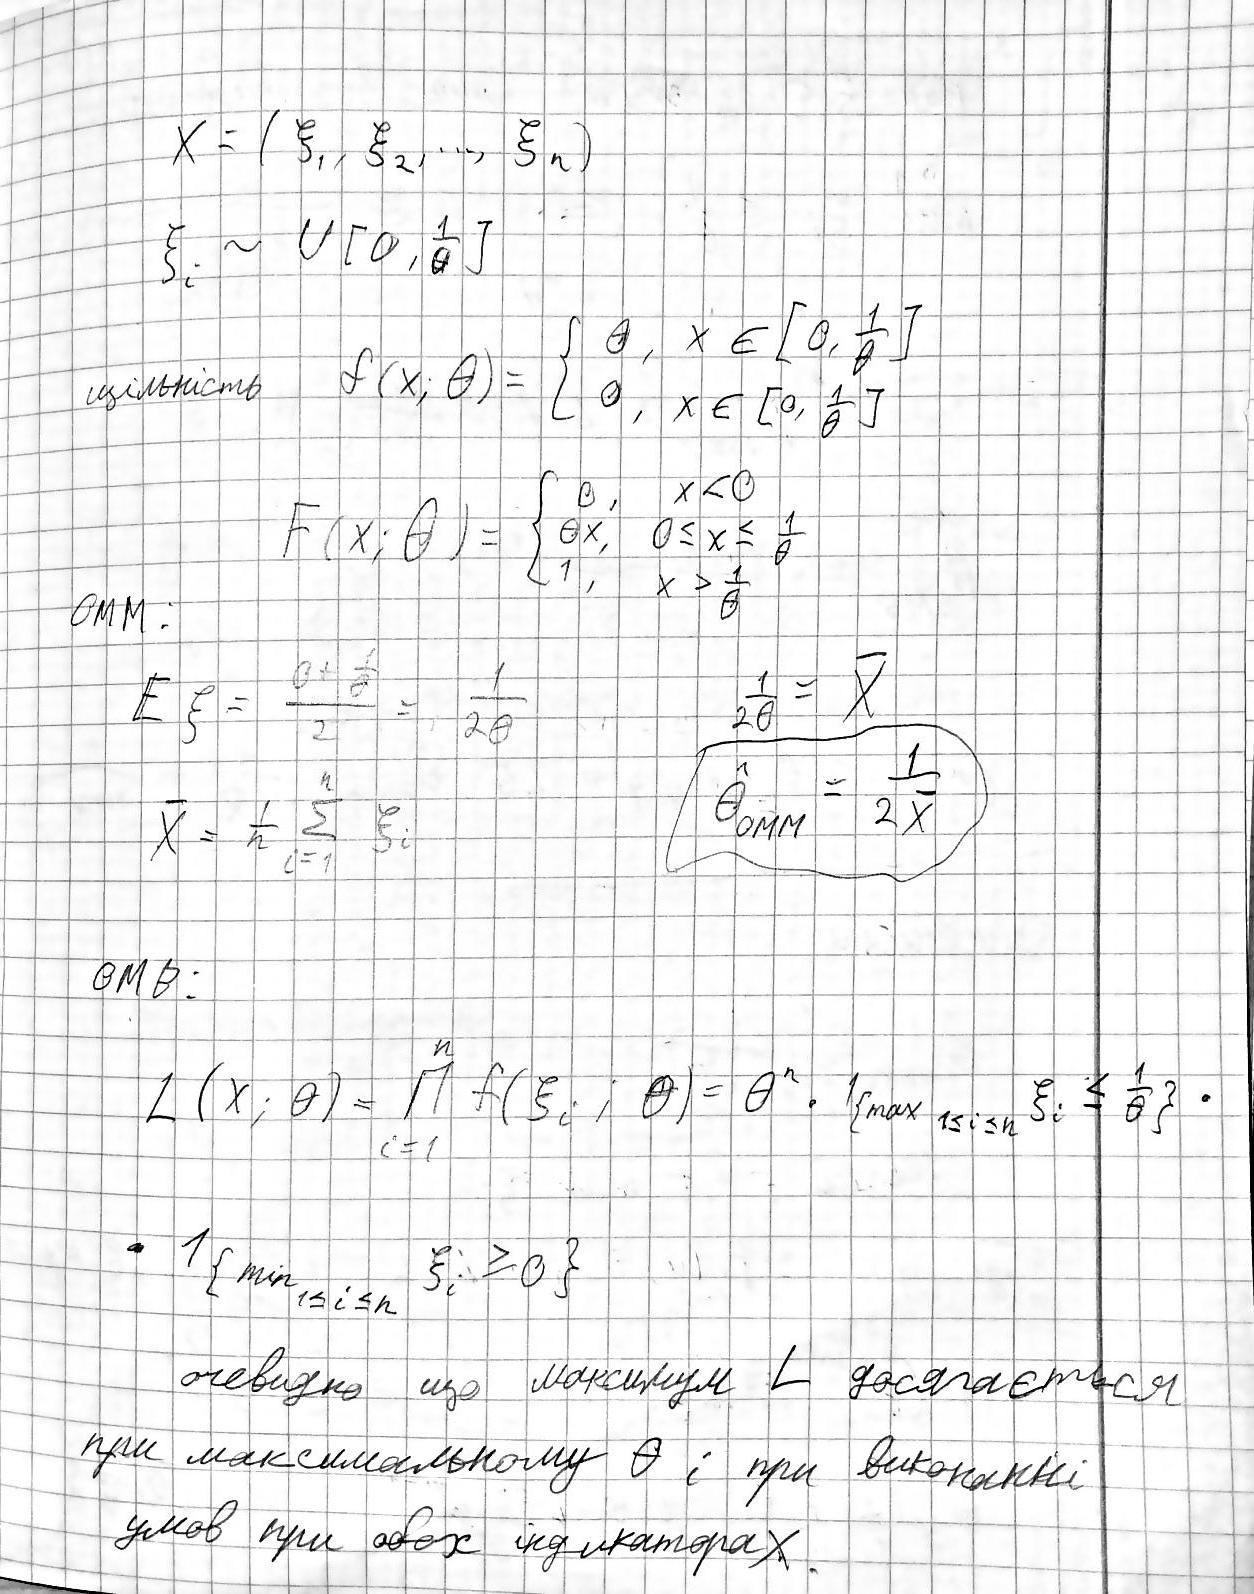

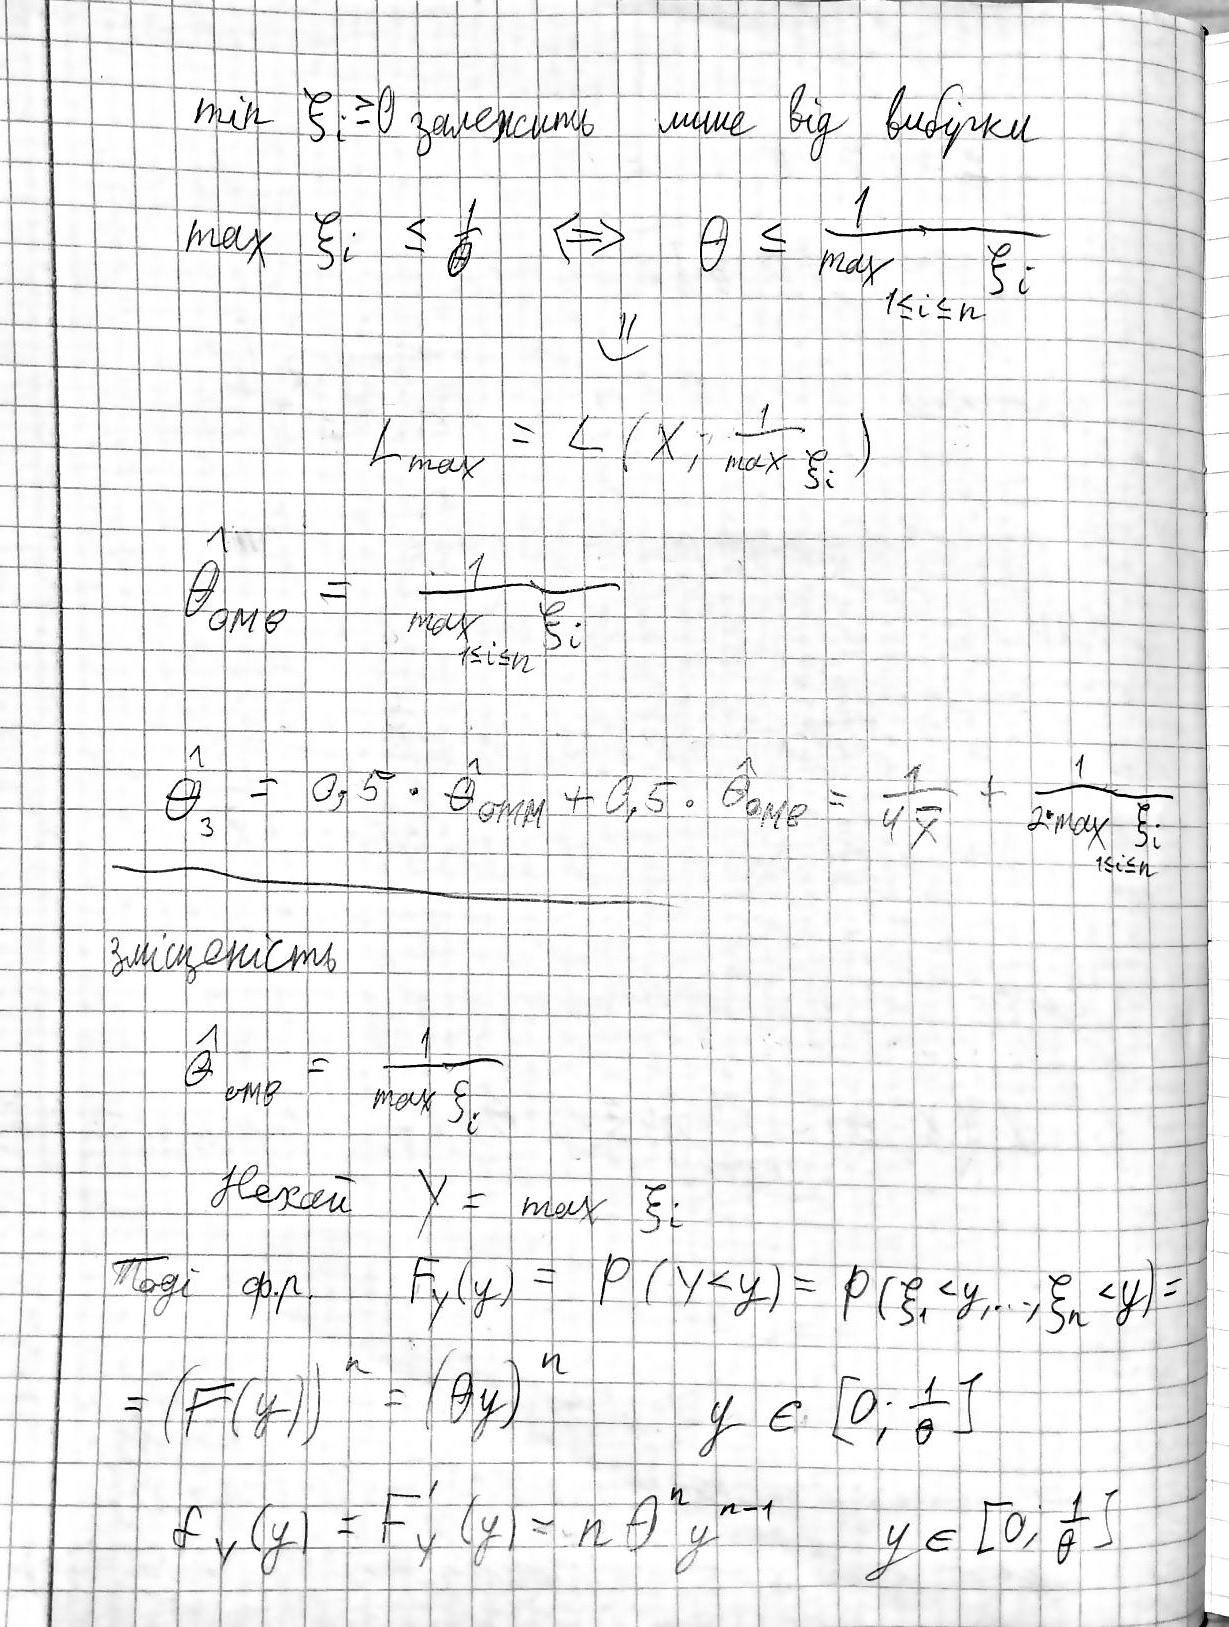

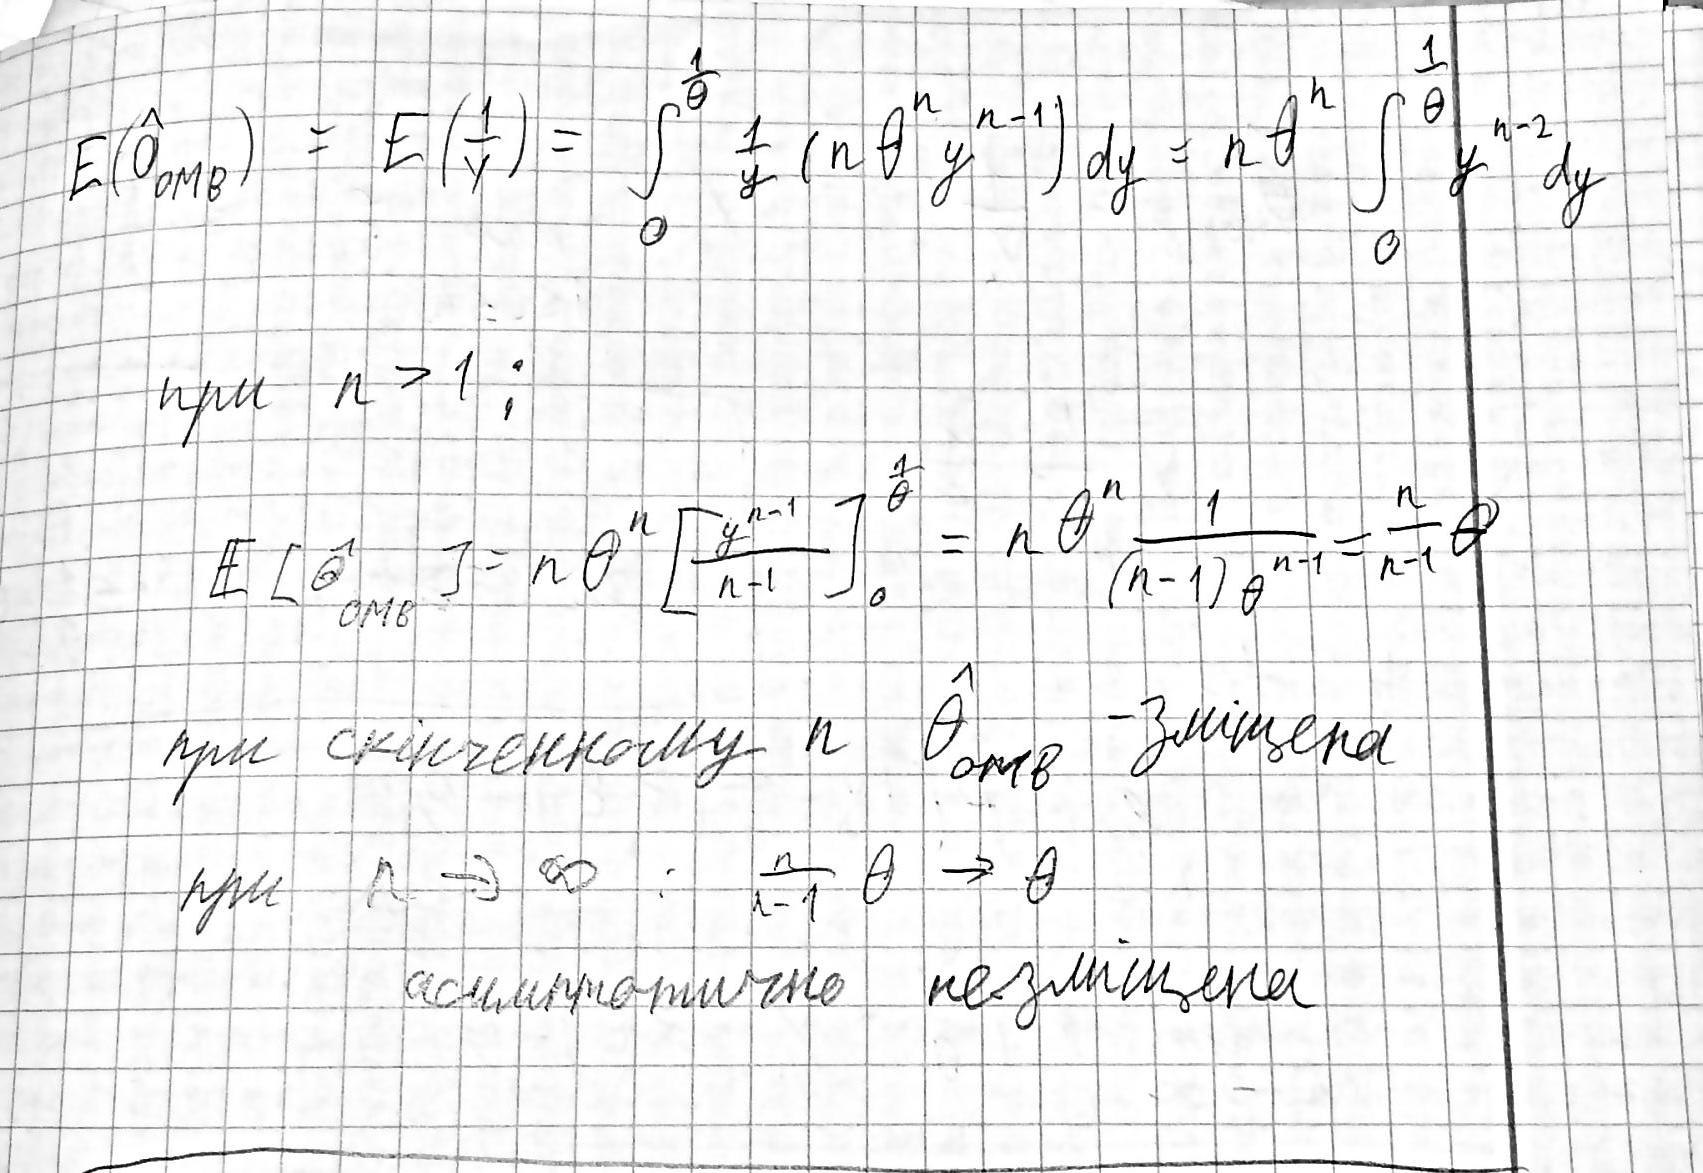

In [16]:
from IPython.display import Image, display

display(Image('p1.jpg', width=500))
display(Image('p2.jpg', width=500))
display(Image('p3.jpg', width=500))

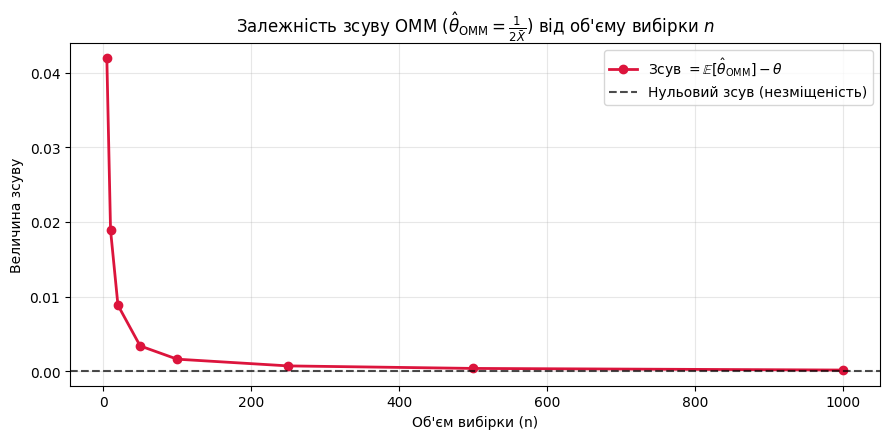

In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

true_theta = 0.5
upper_bound = 1.0 / true_theta
K_sim = 100000

n_values = [5, 10, 20, 50, 100, 250, 500, 1000]
means_omm = []
biases_omm = []

for n in n_values:
    samples = np.random.uniform(low=0.0, high=upper_bound, size=(K_sim, n))

    x_bar = np.mean(samples, axis=1)

    theta_omm = 1.0 / (2.0 * x_bar)

    mean_est = np.mean(theta_omm)
    bias = mean_est - true_theta

    means_omm.append(mean_est)
    biases_omm.append(bias)



plt.figure(figsize=(9, 4.5))
plt.plot(
    n_values,
    biases_omm,
    'o-',
    color='crimson',
    lw=2,
    label=r'Зсув $ = \mathbb{E}[\hat{\theta}_{\text{ОММ}}] - \theta$'
)
plt.axhline(0, color='black', linestyle='--', alpha=0.7, label='Нульовий зсув (незміщеність)')
plt.title(r"Залежність зсуву ОММ ($\hat{\theta}_{\text{ОММ}} = \frac{1}{2\bar{X}}$) від об'єму вибірки $n$")
plt.xlabel("Об'єм вибірки (n)")
plt.ylabel('Величина зсуву')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

З графіку симуляції видно що ОММ зміщена при скінченному n і незміщена на нескінченності(асимптотично)

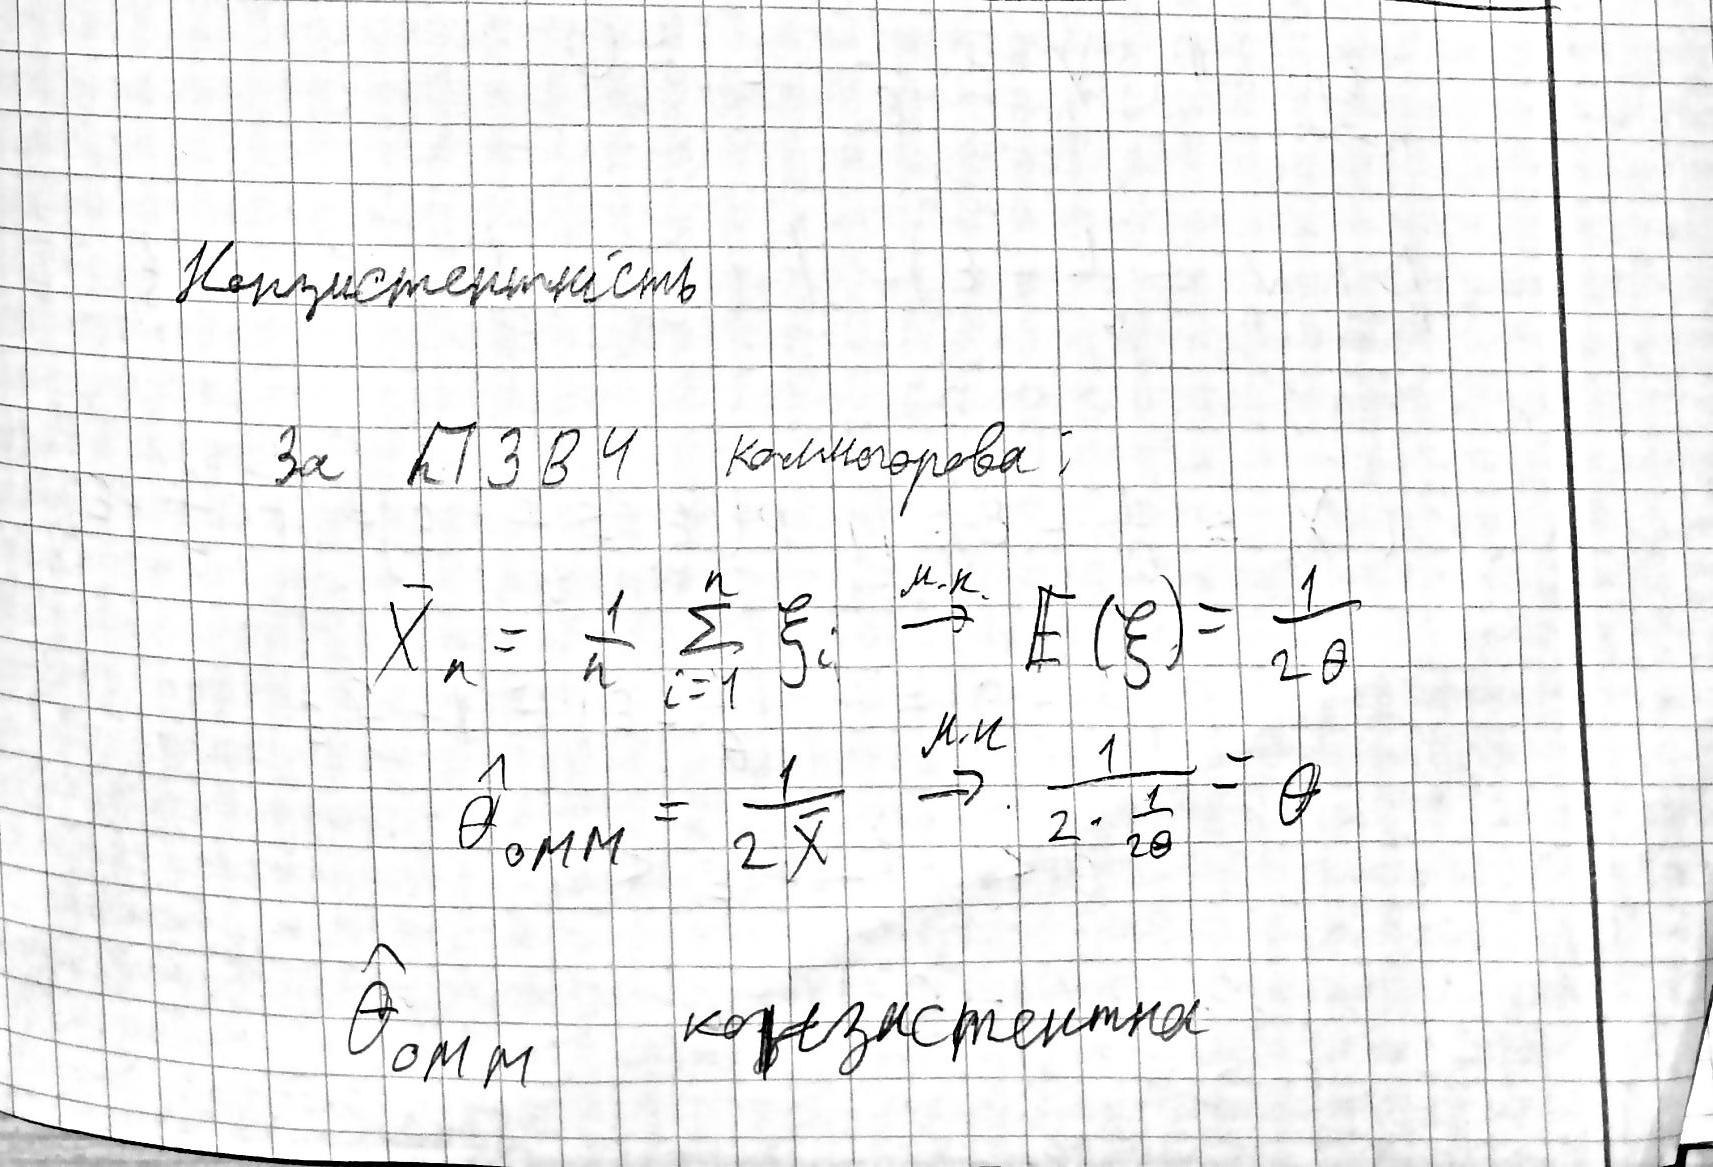

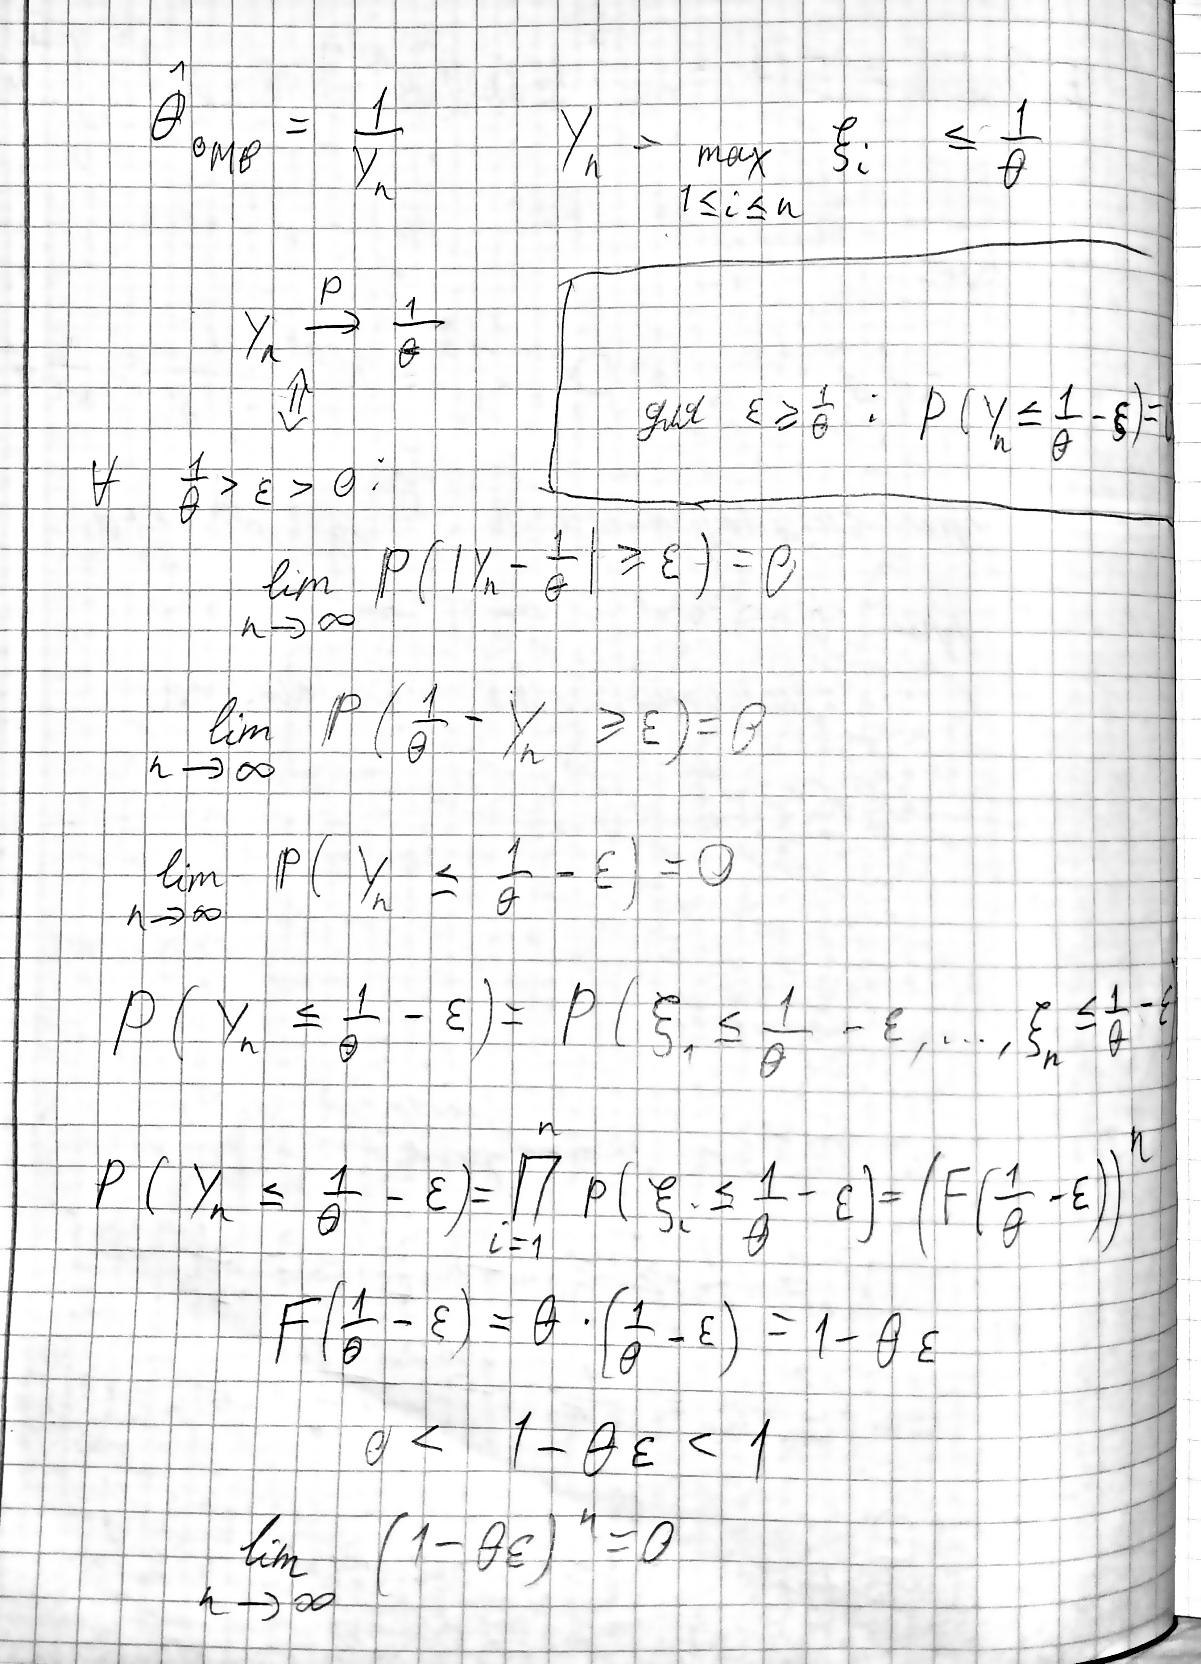

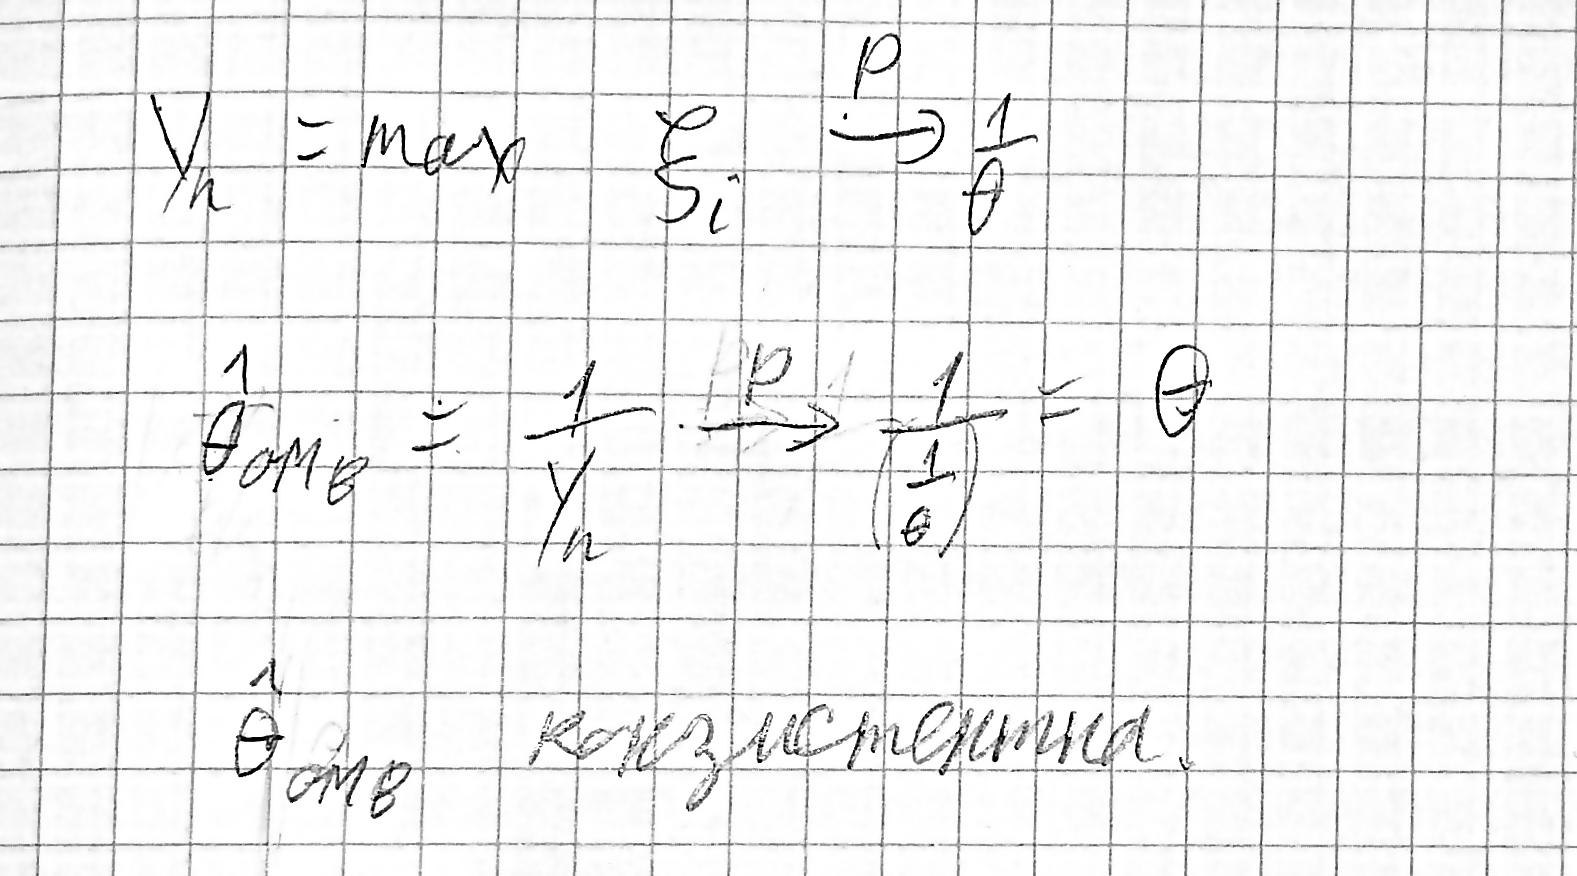

In [17]:
from IPython.display import Image, display

display(Image('p4.jpg', width=500))
display(Image('p5.jpg', width=500))
display(Image('p6.jpg', width=500))

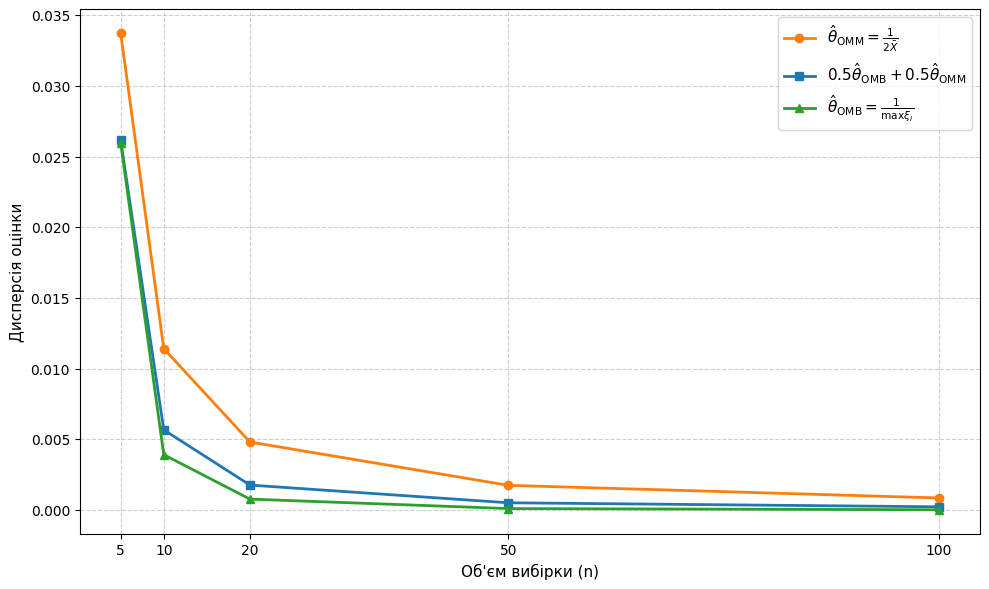

In [12]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


true_theta = 0.5
upper_bound = 1.0 / true_theta
K_sim = 100000


n_values = [5, 10, 20, 50, 100]


vars_omm = []
vars_omv = []
vars_3 = []


for n in n_values:

    samples = np.random.uniform(low=0.0, high=upper_bound, size=(K_sim, n))

    # ОММ
    x_bar = np.mean(samples, axis=1)
    theta_omm = 1.0 / (2.0 * x_bar)

    # ОМВ
    x_max = np.max(samples, axis=1)
    theta_omv = 1.0 / x_max

    # 0.5 * OMB + 0.5 * OMM
    theta_3 = 0.5 * theta_omv + 0.5 * theta_omm

    vars_omm.append(np.var(theta_omm, ddof=1))
    vars_omv.append(np.var(theta_omv, ddof=1))
    vars_3.append(np.var(theta_3, ddof=1))


plt.figure(figsize=(10, 6))
plt.plot(n_values, vars_omm, 'o-', color='#ff7f0e', lw=2, label=r'$\hat{\theta}_{\text{ОММ}} = \frac{1}{2\bar{X}}$')
plt.plot(n_values, vars_3, 's-', color='#1f77b4', lw=2, label=r'$0.5\hat{\theta}_{\text{ОМВ}} + 0.5\hat{\theta}_{\text{ОММ}}$')
plt.plot(n_values, vars_omv, '^-', color='#2ca02c', lw=2, label=r'$\hat{\theta}_{\text{ОМВ}} = \frac{1}{\max {\xi}_i}$')

plt.xlabel("Об'єм вибірки (n)", fontsize=11)
plt.ylabel('Дисперсія оцінки', fontsize=11)
plt.xticks(n_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Всі оцінки є асимптотично незміщеними, і конзистентними.

ОМВ має найменшу дисперсію і є найкращою оцінкою.

# 2. Застосування

Вам дано вибірку X. За її допомогою, оцініть параметри розподілу вибірки, у припущенні, що розподіл - той, що і у вашому варіанті.

1. Побудуйте емпіричну функцію розподілу
2. Побудуйте теоретичний розподіл на основі оцінених параметрів (відповідно до варіанту)
3. Чи відповідає оцінений розподіл розподілу вибірки?
4. Напишіть висновок

In [ ]:
import numpy as np
X = np.array([ 0.06704377, -1.18488209,  0.56093463,  2.28920627, -0.52843351,
        1.64094723, -2.41745054,  0.63898792,  1.694176  ,  0.22749164,
       -0.69864633, -0.16385323,  1.41229225,  1.77067654, -1.32968981,
        0.25585254,  1.09594198,  0.80643983,  0.73262927,  0.97645904])